In [1]:
import os
import sys

assert "jax" not in sys.modules, "jax already imported: you must restart your runtime"
os.environ['XLA_FLAGS'] = "--xla_force_host_platform_device_count=4"

In [2]:
import jax
import jax.numpy as jnp
from jax.typing import ArrayLike

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

from skmisc.loess import loess

from epiweeks import Week

import arviz as az

import numpy as np
import numpyro
import numpyro.distributions as dist

from pyrenew import observation, process, randomvariable
from pyrenew.model.severe_pri_model import (
    HospObservationProcess,
    LatentInfectionProcess,
    PolyVisitObservationProcess,
    PyrenewModel,
)
import pyrenew.transformation as transformation
from pyrenew.deterministic import DeterministicPMF
from pyrenew.metaclass import RandomVariable
from pyrenew.randomvariable import DistributionalVariable, TransformedVariable


/Users/jingjieong/Projects/PyRenew/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def conv(a: ArrayLike, b: ArrayLike) -> ArrayLike:
    """
    Helper function for convolution.
    """
    m = len(a)
    n = len(b)
    c = np.zeros(m + n - 1)

    for i in range(m):
        for j in range(n):
            c[i + j] += a[i] * b[j]
    return c

def format_quarterly_axis(ax):
    """
    Format a Matplotlib time axis to show quarterly ticks (Jan, Apr, Jul, Oct),
    with the year label shown only under January.
    """
    locator = mdates.MonthLocator(bymonth=[1, 4, 7, 10])
    ax.xaxis.set_major_locator(locator)

    def _custom_fmt(x, pos):
        date = mdates.num2date(x)
        if date.month == 1:
            return f"{date.strftime('%b')}\n{date.year}"
        return date.strftime('%b')

    ax.xaxis.set_major_formatter(FuncFormatter(_custom_fmt))
    return ax


In [20]:
d = pd.read_excel('../sg_data/agg_ari_ili.xlsx')

def process_weeks_d(df):
    # Apply get_dates once and combine
    date_temp = df.apply(get_dates, axis=1)
    df = pd.concat([df, date_temp], axis=1)

    # Convert to datetime
    df[['start_date', 'end_date']] = df[['start_date', 'end_date']].apply(pd.to_datetime)

    # Create year-week column
    df['year_week'] = df['year'].astype(str) + "-" + df['epi_week'].astype(str)

    return df

# Apply the Week conversion to each row
def get_dates(row):
    try:
        epi_week = Week(int(row['year']), int(row['epi_week']))
        return pd.Series({
            'start_date': epi_week.startdate(),
            'end_date': epi_week.enddate()
        })
    except Exception as e:
        return pd.Series({
            'start_date': None,
            'end_date': None
        })

d = process_weeks_d(d)

d['ili_influenza_positivity'] = d['ili_influenza_pos'] / d['ili_samples']
d['ari_influenza_positivity'] = d['ari_influenza_pos'] / d['ari_samples']

surv_period = {'start': ['2023-18','2023-44','2024-18','2024-44','2025-18'],
              'end': ['2023-43','2024-17','2024-43','2025-17','2025-39']}

# flu case counts from poly attendances * positivity
d['est_flu_cases'] = d['poly_ari_attendances'] * d['ari_influenza_positivity']
d['est_flu_cases_adj'] = d['poly_ari_attendances_adjusted'] * d['ari_influenza_positivity']

PRIMARY_TARGET_COL = "est_flu_cases_adj"
PRIMARY_TARGET_LABEL = "Adjusted estimated flu cases"
SEVERE_TARGET_COL = "severe_flu"
SEVERE_TARGET_LABEL = "Severe flu hospitalisations"

# d = d.loc[d['est_flu_cases_adj'].notnull()]

d = d.iloc[40:]
d = d.loc[(d['end_date'] <= "2025-12-27"),]
# d = d.iloc[30:] #influenza forecast start date 2024-02-03


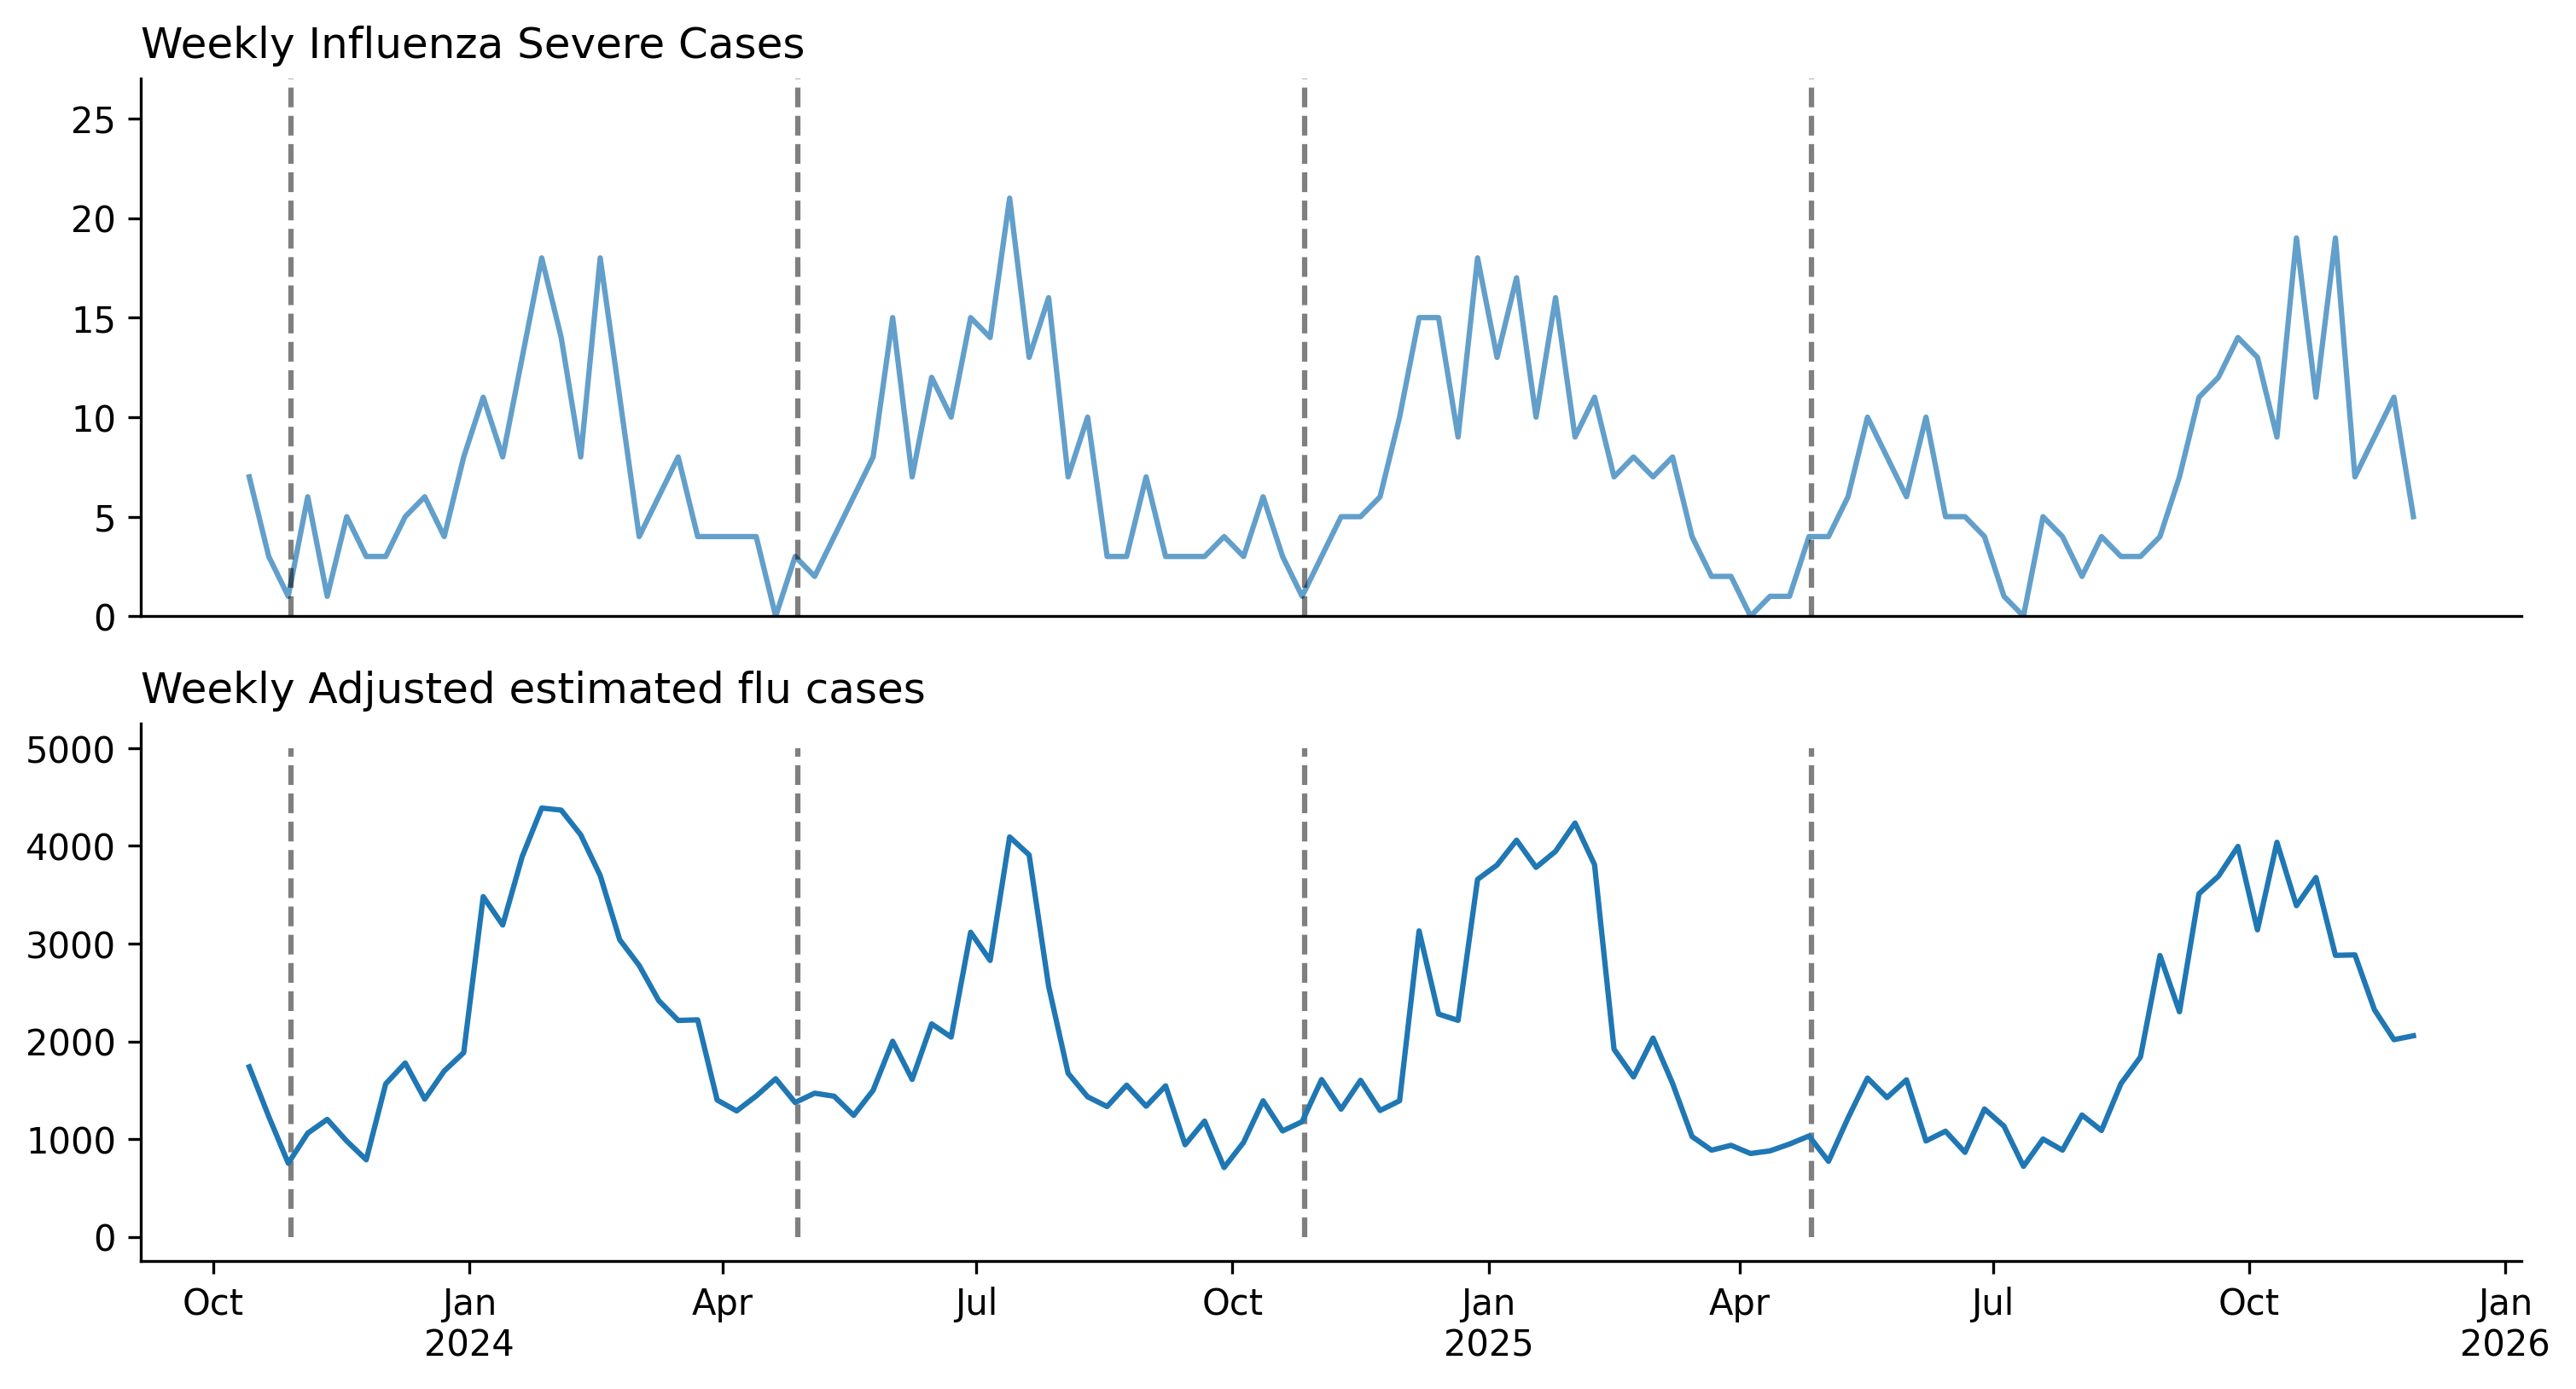

In [22]:
fig,ax = plt.subplots(2,1,figsize = (12,6),dpi=300)
plt.subplots_adjust(hspace = 0.2)

ax[0].plot(d['end_date'],d[SEVERE_TARGET_COL], alpha = 0.7)

for v in surv_period['start']:
        ax[0].vlines(x = d[d['year_week'] == v]['start_date'], ymin = 0, ymax = 30, linestyles='dashed', alpha = 0.5, color = 'black')
        ax[1].vlines(x = d[d['year_week'] == v]['start_date'], ymin = 0, ymax = 5000, linestyles='dashed', alpha = 0.5, color = 'black')

ax[0].set_ylim(0,27)
ax[0].set_xticks([])

ax[1].plot(d['end_date'],d[PRIMARY_TARGET_COL])

for a in ax:
        a.spines['top'].set_visible(False)
        a.spines['right'].set_visible(False)

format_quarterly_axis(ax[1])

ax[0].set_title("Weekly Influenza Severe Cases", loc = 'left')
ax[1].set_title(f"Weekly {PRIMARY_TARGET_LABEL}", loc = 'left')

plt.show()


## Specify Model components

### Generation time, infection to severe and primary care delays

In [23]:
## Generation time interval, Gamma(4.55,0.7) mean 3.2, sd = 1.5
x = jnp.arange(0,20)
gen_time_dist = dist.Gamma(concentration = 4.55, rate = 1/0.7)
gen_time_raw = jnp.exp(gen_time_dist.log_prob(x))
gen_time_norm = gen_time_raw / sum(gen_time_raw)

gen_time_rv = DeterministicPMF(name = 'gen_int', value = gen_time_norm)

## Incubation, Gamma(2.76,0.65) - Infection to symptoms onset = 1-4 days after infection (CDC)
x = jnp.arange(0,10)
incub_dist = dist.Gamma(concentration = 2.76, rate = 1/0.65) #mean = 1.8, sd = 1
incub_raw = jnp.exp(incub_dist.log_prob(x))
incub_norm = incub_raw / sum(incub_raw)

## Onset to severe, Gamma(6.25,0.8) - Onset to severe (6 days on average)
x = jnp.arange(0,15)
ons_severe_dist = dist.Gamma(concentration = 6.25, rate = 1.25) #mean = 5, sd = 2
ons_severe_raw = jnp.exp(ons_severe_dist.log_prob(x))
ons_severe_norm = ons_severe_raw / sum(ons_severe_raw)

# Infection to severe convolution
inf_severe_dist = DeterministicPMF('inf_sev_dist',conv(incub_norm,ons_severe_norm))

## onset to primary care visits
x = jnp.arange(0,7)
ons_primary_dist = dist.Gamma(concentration = 1.8, rate = 1/0.9) #mean 1.6, sd = 1.2
ons_primary_raw = jnp.exp(ons_primary_dist.log_prob(x))
ons_primary_norm = ons_primary_raw / sum(ons_primary_raw)

# Infection to primary care visit convolution
inf_primary_dist = DeterministicPMF('inf_primary_dist', conv(incub_norm, ons_primary_norm))

# Probability of symptomatic given infections
p_sym = TransformedVariable('p_sym',base_rv = DistributionalVariable('p_sym_logodds',
                                                distribution= dist.Normal(0.85,0.6)),
                                    transforms=transformation.SigmoidTransform())

### Ascertainment rate variable for severe and primary care visits

In [24]:
## Ascertainment rate for severe cases (to estimate IHR)
class Alpha_severe_IHR(RandomVariable):

    @staticmethod
    def validate():
        return None

    def sample(self, n = None):
    
        ## p_sym not necessary for this. To be estimated as an infection to severe rate instead.

        p_severe_ihr = DistributionalVariable(name='p_severe_ihr', distribution=dist.Uniform(1e-5, 0.1))

        p_severe_ihr = p_severe_ihr.sample()
        
        p_rho = TransformedVariable('p_rho',base_rv = DistributionalVariable('p_rho_logodds',
                                        distribution= dist.Normal(1.39,0.6)),
                            transforms=transformation.SigmoidTransform())

        p_rho = p_rho.sample()

        alpha_severe = numpyro.deterministic('alpha_severe',p_severe_ihr*p_rho)
        
        return alpha_severe

# alpha_severe_rv = Alpha_severe()
alpha_severe_rv = Alpha_severe_IHR()

## Ascertainment rate for primary care visits
class Alpha_primary(RandomVariable):

    @staticmethod
    def validate():
        return None

    def sample(self, p_sym, n = None):

        p_hseek_dist = DistributionalVariable('p_hseek', distribution = dist.Beta(16,24))
        p_hseek = p_hseek_dist.sample()

        p_visit_dist = DistributionalVariable('p_visit', distribution = dist.Beta(15,85))
        p_visit = p_visit_dist.sample()

        alpha_primary = numpyro.deterministic('alpha_primary',p_sym*p_hseek*p_visit)
        
        return alpha_primary

alpha_primary_rv = Alpha_primary()

n_initialization_points = max(gen_time_rv.sample().size, inf_severe_dist().size, inf_primary_dist().size) - 1

### Latent infection process with Rt

In [25]:
i0_first_obs_n_rv = DistributionalVariable(
    name="I_pre_init",
    distribution=dist.Gamma(concentration=1.0, rate=1.0 / 50.0),
)

# The random walk on log Rt, with a configurable scale so screening runs can
# test slightly more or less responsive trajectories without rewriting the model.
class RtRandomWalk(RandomVariable):
    def __init__(self, sd_scale=0.025, init_scale=0.2):
        self.sd_scale = sd_scale
        self.init_scale = init_scale

    def validate(self):
        pass

    def sample(self, n: int, **kwargs) -> tuple:
        sd_rt = numpyro.sample(
            "Rt_random_walk_sd",
            dist.HalfNormal(self.sd_scale),
        )

        step_rv = randomvariable.DistributionalVariable(
            name="rw_step_rv",
            distribution=dist.Normal(0, sd_rt),
        )

        rt_init_rv = randomvariable.DistributionalVariable(
            name="init_log_rt",
            distribution=dist.Normal(0, self.init_scale),
        )

        base_rv = process.RandomWalk(
            name="log_rt",
            step_rv=step_rv,
        )

        rt_rv = randomvariable.TransformedVariable(
            name="Rt_rv",
            base_rv=base_rv,
            transforms=transformation.ExpTransform(),
        )
        init_rt = rt_init_rv.sample()

        return rt_rv.sample(n=n, init_vals=init_rt, **kwargs)


def build_latent_process(
    feedback,
    rt_rw_scale=0.025,
    feedback_scale=0.002,
):
    rtproc = RtRandomWalk(sd_scale=rt_rw_scale)
    inf_feedback_strength_rv = DistributionalVariable(
        "inf_feedback_raw",
        dist.HalfNormal(feedback_scale),
    )

    return LatentInfectionProcess(
        i0_first_obs_n_rv=i0_first_obs_n_rv,
        Rt_process_rv=rtproc,
        feedback=feedback,
        generation_interval_pmf_rv=gen_time_rv,
        infection_feedback_strength_rv=inf_feedback_strength_rv,
        infection_feedback_pmf_rv=gen_time_rv,
        n_initialization_points=n_initialization_points,
    )


### Observation process

In [26]:
# Observation model for severe cases - negative binomial
# Original broad raw^-2 prior kept for reference.
# nb_conc_sev_rv = TransformedVariable(
#     "concentration_severe",
#     randomvariable.DistributionalVariable(
#         name="concentration_severe_raw",
#         distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
#     ),
#     transformation.PowerTransform(-2),
# )
log_nb_conc_sev_rv = randomvariable.DistributionalVariable(
    name="log_concentration_severe",
    distribution=dist.Normal(loc=jnp.log(40.0), scale=0.5),
)
nb_conc_sev_rv = TransformedVariable(
    "concentration_severe",
    log_nb_conc_sev_rv,
    transformation.ExpTransform(),
)

# now we define the observation process
obs_sev = observation.NegativeBinomialObservation(
    "negbinom_severe_rv",
    concentration_rv=nb_conc_sev_rv,    
)

hosp_obs = HospObservationProcess(p_hosp_mean_rv = alpha_severe_rv,
                                       inf_to_hosp_rv=inf_severe_dist,
                                       hosp_obs_process_rv=obs_sev,)
                                       

# Observation model for poly visit cases - negative binomial
# Original broad raw^-2 prior kept for reference.
# nb_conc_primary_rv = TransformedVariable(
#     "concentration_primary",
#     randomvariable.DistributionalVariable(
#         name="concentration_primary_raw",
#         distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
#     ),
#     transformation.PowerTransform(-2),
# )
log_nb_conc_primary_rv = randomvariable.DistributionalVariable(
    name="log_concentration_primary",
    distribution=dist.Normal(loc=jnp.log(30.0), scale=0.5),
)
nb_conc_primary_rv = TransformedVariable(
    "concentration_primary",
    log_nb_conc_primary_rv,
    transformation.ExpTransform(),
)

# now we define the observation process
obs_primary = observation.NegativeBinomialObservation(
    "negbinom_primary_rv",
    concentration_rv=nb_conc_primary_rv,    
)

poly_obs = PolyVisitObservationProcess(p_poly_mean_rv = alpha_primary_rv,
                                       inf_to_poly_rv=inf_primary_dist,
                                       poly_obs_process_rv=obs_primary,
                                       p_sym=p_sym)

### Forecasts


In [27]:
HORIZON_PREFIXES = {
    1: "one_week",
    2: "two_week",
    3: "three_week",
    4: "four_week",
}

def maybe_smooth_series(dates, values, use_loess):
    values = np.asarray(values, dtype=float)
    if not use_loess:
        return values
    return loess(dates, values).predict(dates).values

def run_model(
    model,
    fit_d,
    use_loess=True,
    primary_target_col=PRIMARY_TARGET_COL,
    mcmc_config=None,
):
    if mcmc_config is None:
        mcmc_config = MCMC_CONFIG

    observed_hosp = maybe_smooth_series(
        fit_d["end_date"],
        fit_d[SEVERE_TARGET_COL],
        use_loess=use_loess,
    )
    observed_poly = maybe_smooth_series(
        fit_d["end_date"],
        fit_d[primary_target_col],
        use_loess=use_loess,
    )

    model.run(
        num_samples=mcmc_config["num_samples"],
        num_warmup=mcmc_config["num_warmup"],
        rng_key=jax.random.key(mcmc_config["rng_seed"]),
        mcmc_args=dict(
            progress_bar=False,
            num_chains=mcmc_config["num_chains"],
        ),
        data_observed_poly=observed_poly,
        data_observed_hosp=observed_hosp,
        sample_poly_visits=True,
        sample_hospital_admissions=True,
    )

    return model

def forecast(model, fit_d, weeks_ahead):
    n_forecast_days = weeks_ahead * 7

    ppc_samples = model.posterior_predictive(
        n_datapoints=len(fit_d) * 7 + n_forecast_days
    )

    return az.from_numpyro(
        posterior=model.mcmc,
        posterior_predictive=ppc_samples,
    )

def stack_weekly_draws(idata, site_name, total_weeks):
    return np.asarray(idata.posterior_predictive[site_name]).reshape(-1, total_weeks)

def summarize_future_weekly(
    idata,
    observed_site_name,
    mu_site_name,
    total_weeks,
    weeks_ahead,
):
    observed_draws = stack_weekly_draws(idata, observed_site_name, total_weeks)
    mu_draws = stack_weekly_draws(idata, mu_site_name, total_weeks)

    future_observed = observed_draws[:, -weeks_ahead:]
    future_mu = mu_draws[:, -weeks_ahead:]
    quantiles = np.quantile(
        future_observed,
        q=[0.025, 0.25, 0.5, 0.75, 0.975],
        axis=0,
    )

    return {
        "pred": quantiles[2],
        "pred_mu": np.median(future_mu, axis=0),
        "lower2.5": quantiles[0],
        "lower25": quantiles[1],
        "upper75": quantiles[3],
        "upper97.5": quantiles[4],
    }


In [28]:
forecast_ahead = 4  # weeks

# Fast screen mode runs a smaller origin subset with a lighter MCMC budget.
# Set this to False once a candidate is worth the full rolling backtest.
FAST_SCREEN_MODE = False

# Try 16 or 20 weeks here before promoting a model to the full 24-week run.
fit_length = 12 if FAST_SCREEN_MODE else 12

SCREEN_END_DATES = [
    pd.Timestamp("2023-06-17"),
    pd.Timestamp("2023-07-15"),
    pd.Timestamp("2023-07-29"),
    pd.Timestamp("2023-08-12"),
    pd.Timestamp("2023-09-16"),
    pd.Timestamp("2023-10-07"),
    pd.Timestamp("2023-11-18"),
    pd.Timestamp("2023-12-23"),
    pd.Timestamp("2024-01-13"),
    pd.Timestamp("2024-02-10"),
    pd.Timestamp("2024-03-09"),
    pd.Timestamp("2024-04-06"),
    pd.Timestamp("2024-05-18"),
    pd.Timestamp("2024-06-08"),
    pd.Timestamp("2024-07-13"),
    pd.Timestamp("2024-08-03"),
    pd.Timestamp("2024-08-24"),
    pd.Timestamp("2024-09-21"),
    pd.Timestamp("2024-11-30"),
    pd.Timestamp("2024-12-28"),
    pd.Timestamp("2025-01-18"),
    pd.Timestamp("2025-02-08"),
    pd.Timestamp("2025-03-08"),
    pd.Timestamp("2025-04-19"),
    pd.Timestamp("2025-07-26"),
    pd.Timestamp("2025-09-20"),
    pd.Timestamp("2025-09-27"),
    pd.Timestamp("2025-10-25")
  ] if FAST_SCREEN_MODE else None

FULL_MCMC_CONFIG = {
    "num_samples": 1000,
    "num_warmup": 1000,
    "num_chains": 2,
    "rng_seed": 54,
}
SCREEN_MCMC_CONFIG = {
    "num_samples": 300,
    "num_warmup": 300,
    "num_chains": 1,
    "rng_seed": 54,
}
MCMC_CONFIG = SCREEN_MCMC_CONFIG if FAST_SCREEN_MODE else FULL_MCMC_CONFIG

OUTPUT_DIR = (
    "../forecast_results/influenza/fast_screen"
    if FAST_SCREEN_MODE
    else "../forecast_results/influenza"
)
WRITE_FORECAST_RESULTS = True
os.makedirs(OUTPUT_DIR, exist_ok=True)

rolling_start_window = np.arange(0, len(d) - forecast_ahead - fit_length + 1)
rolling_end_window = rolling_start_window + fit_length

print(
    "Run mode:",
    "fast screen" if FAST_SCREEN_MODE else "full rolling backtest",
)
print("Fit length:", fit_length, "weeks")
print("MCMC config:", MCMC_CONFIG)
if SCREEN_END_DATES is not None:
    print(
        "Screen origins:",
        [screen_date.strftime("%Y-%m-%d") for screen_date in SCREEN_END_DATES],
    )
    print("Output dir:", OUTPUT_DIR)


Run mode: full rolling backtest
Fit length: 12 weeks
MCMC config: {'num_samples': 1000, 'num_warmup': 1000, 'num_chains': 2, 'rng_seed': 54}


In [29]:
TUNING_GRID_MODE = False

# Compact first-pass tuning grid: control plus the most promising Loess + FB
# settings. Expand this list if the medium screen needs a broader sweep.
TUNING_GRID_COMBOS = [
    (0.040, 0.0005),  # current control
    (0.040, 0.00075),
    (0.040, 0.001),
    (0.050, 0.0005),
    (0.050, 0.00075),
    (0.050, 0.001),
    (0.060, 0.0005),
    (0.060, 0.00075),
    (0.060, 0.001),
]

DEFAULT_VIEW_MODEL_NAME = "NoLoess + FB rw=0.060 fb=0.0010"

def scale_slug(value, decimals=4):
    return f"{value:.{decimals}f}".replace(".", "p")

def build_tuning_grid_configs(
    fit_length_value,
    combos=TUNING_GRID_COMBOS,
    use_loess=False,
    feedback=True,
    model_prefix="NoLoess + FB",
):
    configs = {}
    for rt_rw_scale, feedback_scale in combos:
        model_name = (
            f"{model_prefix} rw={rt_rw_scale:.3f} fb={feedback_scale:.4f}"
        )
        file_stub = (
            "loess_feedback_logconc_"
            f"fit{fit_length_value}_"
            f"rw{scale_slug(rt_rw_scale, decimals=3)}_"
            f"fb{scale_slug(feedback_scale, decimals=4)}"
        )
        configs[model_name] = {
            "model_name": model_name,
            "file_stub": file_stub,
            "use_loess": use_loess,
            "feedback": feedback,
            "fit_length": fit_length_value,
            "rt_rw_scale": rt_rw_scale,
            "feedback_scale": feedback_scale,
        }
    return configs

BASE_MODEL_CONFIGS = {
    # "Loess + FB": {
    #     "model_name": "Loess + FB",
    #     "file_stub": "fit12_loess_feedback_logconc_rt0p05_fb0p0005",
    #     "use_loess": True,
    #     "feedback": True,
    #     "fit_length": fit_length,
    #     "rt_rw_scale": 0.05,
    #     "feedback_scale": 0.0005,
    # },
    "NoLoess + FB": {
    "model_name": "NoLoess + FB",
    "file_stub": "fit12_noloess_feedback_logconc_rt0p06_fb0p001",
    "use_loess": False,
    "feedback": True,
    "fit_length": fit_length,
    "rt_rw_scale": 0.06,
    "feedback_scale": 0.001,
    },
}

MODEL_CONFIGS = (
    build_tuning_grid_configs(fit_length_value=fit_length)
    if TUNING_GRID_MODE
    else BASE_MODEL_CONFIGS
)

if DEFAULT_VIEW_MODEL_NAME not in MODEL_CONFIGS:
    DEFAULT_VIEW_MODEL_NAME = next(iter(MODEL_CONFIGS))

print("Configured models:")
for model_name in MODEL_CONFIGS:
    print(f"  - {model_name}")
print("Default view model:", DEFAULT_VIEW_MODEL_NAME)

OUTCOME_SPEC = {
    "outcome": "pri",
    "observed_site_name": "negbinom_primary_rv",
    "mu_site_name": "mu_poly_weekly",
    "target_col": PRIMARY_TARGET_COL,
    "target_label": PRIMARY_TARGET_LABEL,
}

def build_model(config):
    latent_process = build_latent_process(
        feedback=config["feedback"],
        rt_rw_scale=config.get("rt_rw_scale", 0.025),
        feedback_scale=config.get("feedback_scale", 0.002),
    )
    return PyrenewModel(
        population_size=1,
        latent_infection_process_rv=latent_process,
        poly_visit_obs_process_rv=poly_obs,
        hosp_admit_obs_process_rv=hosp_obs,
    )

def select_rolling_windows(fit_length_value, screen_end_dates=None):
    start_window = np.arange(
        0,
        len(d) - forecast_ahead - fit_length_value + 1,
    )
    end_window = start_window + fit_length_value
    windows = list(zip(start_window, end_window))

    if screen_end_dates is None:
        return windows

    desired_dates = {pd.Timestamp(x) for x in screen_end_dates}
    found_dates = set()
    selected_windows = []

    for start, end in windows:
        origin_date = pd.Timestamp(d.iloc[end - 1]["end_date"])
        if origin_date in desired_dates:
            selected_windows.append((start, end))
            found_dates.add(origin_date)

    missing_dates = sorted(desired_dates - found_dates)
    if missing_dates:
        print(
            "Missing requested screen origins:",
            [missing_date.strftime("%Y-%m-%d") for missing_date in missing_dates],
        )

    return selected_windows

def init_forecast_dict():
    forecast_dict = {
        "model_name": [],
        "outcome": [],
        "target_series": [],
        "target_label": [],
        "use_loess": [],
        "feedback": [],
        "fit_length": [],
        "forecast_ahead": [],
        "year": [],
        "epi_week": [],
        "end_date": [],
        "obs": [],
    }
    for prefix in HORIZON_PREFIXES.values():
        for suffix in [
            "pred",
            "pred_mu",
            "lower2.5",
            "lower25",
            "upper75",
            "upper97.5",
            "date",
            "obs",
        ]:
            forecast_dict[f"{prefix}_{suffix}"] = []
    return forecast_dict

def append_forecast_row(forecast_dict, fit_d, fore_d, summary, config):
    forecast_dict["model_name"].append(config["model_name"])
    forecast_dict["outcome"].append(OUTCOME_SPEC["outcome"])
    forecast_dict["target_series"].append(OUTCOME_SPEC["target_col"])
    forecast_dict["target_label"].append(OUTCOME_SPEC["target_label"])
    forecast_dict["use_loess"].append(config["use_loess"])
    forecast_dict["feedback"].append(config["feedback"])
    forecast_dict["fit_length"].append(len(fit_d))
    forecast_dict["forecast_ahead"].append(forecast_ahead)

    last_fit = fit_d.iloc[-1]
    forecast_dict["year"].append(last_fit["year"])
    forecast_dict["epi_week"].append(last_fit["epi_week"])
    forecast_dict["end_date"].append(last_fit["end_date"])
    forecast_dict["obs"].append(last_fit[OUTCOME_SPEC["target_col"]])

    for horizon, prefix in HORIZON_PREFIXES.items():
        future_row = fore_d.iloc[len(fit_d) + horizon - 1]
        forecast_dict[f"{prefix}_pred"].append(summary["pred"][horizon - 1])
        forecast_dict[f"{prefix}_pred_mu"].append(summary["pred_mu"][horizon - 1])
        forecast_dict[f"{prefix}_lower2.5"].append(summary["lower2.5"][horizon - 1])
        forecast_dict[f"{prefix}_lower25"].append(summary["lower25"][horizon - 1])
        forecast_dict[f"{prefix}_upper75"].append(summary["upper75"][horizon - 1])
        forecast_dict[f"{prefix}_upper97.5"].append(summary["upper97.5"][horizon - 1])
        forecast_dict[f"{prefix}_date"].append(future_row["end_date"])
        forecast_dict[f"{prefix}_obs"].append(future_row[OUTCOME_SPEC["target_col"]])

def run_rolling_forecasts(config):
    forecast_dict = init_forecast_dict()
    windows = select_rolling_windows(
        fit_length_value=config.get("fit_length", fit_length),
        screen_end_dates=SCREEN_END_DATES,
    )

    if not windows:
        raise ValueError(
            f"No rolling windows found for {config['model_name']} "
            f"with fit_length={config.get('fit_length', fit_length)}"
        )

    print(
        f"fitting {config['model_name']} on {len(windows)} origin(s); "
        f"fit_length={config.get('fit_length', fit_length)}, "
        f"rt_rw_scale={config.get('rt_rw_scale', 0.025)}, "
        f"feedback_scale={config.get('feedback_scale', 0.002)}"
    )

    for step, (start, end) in enumerate(windows):
        fit_d = d.iloc[start:end].copy()
        fore_d = d.iloc[start : (end + forecast_ahead)].copy()

        print(f"  step {step + 1}/{len(windows)} ending {fit_d.iloc[-1]['end_date']:%Y-%m-%d}")
        fitted_model = run_model(
            build_model(config),
            fit_d=fit_d,
            use_loess=config["use_loess"],
            primary_target_col=PRIMARY_TARGET_COL,
            mcmc_config=MCMC_CONFIG,
        )
        idata = forecast(fitted_model, fit_d, weeks_ahead=forecast_ahead)
        summary = summarize_future_weekly(
            idata,
            observed_site_name=OUTCOME_SPEC["observed_site_name"],
            mu_site_name=OUTCOME_SPEC["mu_site_name"],
            total_weeks=len(fore_d),
            weeks_ahead=forecast_ahead,
        )
        append_forecast_row(
            forecast_dict,
            fit_d=fit_d,
            fore_d=fore_d,
            summary=summary,
            config=config,
        )

    return pd.DataFrame(forecast_dict)


Configured models:
  - NoLoess + FB
Default view model: NoLoess + FB


In [30]:
forecast_runs = {}

for model_name, config in MODEL_CONFIGS.items():
    forecast_df = run_rolling_forecasts(config)
    if WRITE_FORECAST_RESULTS:
        forecast_df.to_csv(
            os.path.join(OUTPUT_DIR, f"pri_{config['file_stub']}.csv"),
            index=False,
        )
    forecast_runs[model_name] = forecast_df

fore_pri_df_default = forecast_runs.get(DEFAULT_VIEW_MODEL_NAME)
fore_pri_df_loess_fb = (
    fore_pri_df_default if TUNING_GRID_MODE else forecast_runs.get("Loess + FB")
)
fore_pri_df_noloess_fb = forecast_runs.get("No Loess + FB")
fore_pri_df_loess_nofb = forecast_runs.get("Loess + No FB")
fore_pri_df_noloess_nofb = forecast_runs.get("No Loess + No FB")


fitting NoLoess + FB on 101 origin(s); fit_length=12, rt_rw_scale=0.06, feedback_scale=0.001
  step 1/101 ending 2023-12-30
  step 2/101 ending 2024-01-06
  step 3/101 ending 2024-01-13
  step 4/101 ending 2024-01-20
  step 5/101 ending 2024-01-27
  step 6/101 ending 2024-02-03
  step 7/101 ending 2024-02-10
  step 8/101 ending 2024-02-17
  step 9/101 ending 2024-02-24
  step 10/101 ending 2024-03-02
  step 11/101 ending 2024-03-09
  step 12/101 ending 2024-03-16
  step 13/101 ending 2024-03-23
  step 14/101 ending 2024-03-30
  step 15/101 ending 2024-04-06
  step 16/101 ending 2024-04-13
  step 17/101 ending 2024-04-20
  step 18/101 ending 2024-04-27
  step 19/101 ending 2024-05-04
  step 20/101 ending 2024-05-11
  step 21/101 ending 2024-05-18
  step 22/101 ending 2024-05-25
  step 23/101 ending 2024-06-01
  step 24/101 ending 2024-06-08
  step 25/101 ending 2024-06-15
  step 26/101 ending 2024-06-22
  step 27/101 ending 2024-06-29
  step 28/101 ending 2024-07-06
  step 29/101 ending

### Visualise 1 to 4 weeks ahead


In [ ]:
FORECAST_PLOT_SPECS = [
    ("one_week", "one-week ahead forecast", None),
    ("two_week", "two-week ahead forecast", "orange"),
    ("three_week", "three-week ahead forecast", "green"),
    ("four_week", "four-week ahead forecast", "red"),
]

def plot_horizon_forecasts(fore_df, observed_col, observed_df=d):
    fig, ax = plt.subplots(2, 2, figsize=(12, 6), dpi=300)
    ax = ax.ravel()
    observed_window = observed_df.iloc[
        rolling_start_window[0]:(rolling_end_window[-1] + forecast_ahead)
    ]

    for axis, (prefix, title, color) in zip(ax, FORECAST_PLOT_SPECS):
        line_kwargs = {"marker": "o", "alpha": 0.7}
        if color is not None:
            line_kwargs["color"] = color

        axis.plot(
            fore_df[f"{prefix}_date"],
            fore_df[f"{prefix}_pred"],
            **line_kwargs,
        )
        axis.set_title(title, loc="left")
        axis.plot(
            observed_window["end_date"],
            observed_window[observed_col],
            marker="o",
            alpha=0.6,
            color="k",
        )
        axis.axvspan(
            observed_window.iloc[0]["end_date"],
            observed_window.iloc[fit_length]["end_date"],
            facecolor="grey",
            alpha=0.15,
            zorder=1,
            edgecolor="black",
        )
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)
        format_quarterly_axis(axis)

    plt.tight_layout()
    plt.show()


In [ ]:
if fore_pri_df_default is not None and not fore_pri_df_default.empty:
    plot_horizon_forecasts(fore_pri_df_default, PRIMARY_TARGET_COL)
else:
    print("No forecast dataframe available for the horizon plot.")


### Load data


In [ ]:
from pathlib import Path

FORECAST_FILES = {
    model_name: os.path.join(OUTPUT_DIR, f"pri_{config['file_stub']}.csv")
    for model_name, config in MODEL_CONFIGS.items()
}

FORECAST_SEARCH_DIRS = [
    Path(OUTPUT_DIR),
    Path("../forecast_results/influenza"),
    Path("../forecast_results/influenza/fast_screen"),
]

def normalize_forecast_search_dirs(search_dirs=None):
    dirs = FORECAST_SEARCH_DIRS if search_dirs is None else search_dirs
    if isinstance(dirs, (str, Path, os.PathLike)):
        dirs = [dirs]
    normalized = []
    for directory in dirs:
        directory = Path(directory).expanduser()
        if directory not in normalized:
            normalized.append(directory)
    return normalized

def resolve_forecast_path(forecast_input, search_dirs=None):
    candidate = Path(forecast_input).expanduser()
    if candidate.exists():
        return candidate

    tried = [str(candidate)]
    for directory in normalize_forecast_search_dirs(search_dirs):
        resolved = directory / forecast_input
        tried.append(str(resolved))
        if resolved.exists():
            return resolved

    tried_text = "\n  - ".join(tried)
    raise FileNotFoundError(
        f"Could not resolve forecast file '{forecast_input}'. Tried:\n  - {tried_text}"
    )

def infer_forecast_label(forecast_df, path):
    if "model_name" in forecast_df.columns and forecast_df["model_name"].dropna().size:
        return str(forecast_df["model_name"].dropna().iloc[0])
    return Path(path).stem

def list_available_forecast_files(pattern="pri_*.csv", search_dirs=None):
    rows = []
    seen_paths = set()
    for directory in normalize_forecast_search_dirs(search_dirs):
        if not directory.exists():
            continue
        for path in sorted(directory.glob(pattern)):
            resolved = path.resolve()
            if resolved in seen_paths:
                continue
            seen_paths.add(resolved)
            rows.append(
                {
                    "filename": path.name,
                    "path": str(path),
                    "directory": str(path.parent),
                }
            )
    return pd.DataFrame(rows)

def load_forecast_df(
    path,
    date_cols=(
        "end_date",
        "one_week_date",
        "two_week_date",
        "three_week_date",
        "four_week_date",
    ),
):
    df = pd.read_csv(path)
    unnamed_cols = [col for col in df.columns if col.startswith("Unnamed:")]
    if unnamed_cols:
        df = df.drop(columns=unnamed_cols)

    for col in date_cols:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

    return df

def load_all_forecasts(file_map=FORECAST_FILES, require_all=False):
    loaded = {}
    missing = {}

    for model_name, forecast_path in file_map.items():
        if os.path.exists(forecast_path):
            loaded[model_name] = load_forecast_df(forecast_path)
        else:
            missing[model_name] = forecast_path

    if missing:
        print("Missing forecast files:")
        for model_name, forecast_path in missing.items():
            print(f"  {model_name}: {forecast_path}")
        if require_all:
            missing_paths = ", ".join(missing.values())
            raise FileNotFoundError(f"Missing forecast files: {missing_paths}")

    return loaded, missing

def load_selected_forecasts(forecast_inputs, search_dirs=None):
    if forecast_inputs is None:
        return {}, {}

    if isinstance(forecast_inputs, (str, Path, os.PathLike)):
        items = [(None, forecast_inputs)]
    elif isinstance(forecast_inputs, dict):
        items = list(forecast_inputs.items())
    else:
        items = [(None, forecast_input) for forecast_input in forecast_inputs]

    loaded = {}
    resolved_paths = {}
    for label, forecast_input in items:
        resolved_path = resolve_forecast_path(
            forecast_input,
            search_dirs=search_dirs,
        )
        forecast_df = load_forecast_df(resolved_path)
        label = label or infer_forecast_label(forecast_df, resolved_path)
        loaded[label] = forecast_df
        resolved_paths[label] = str(resolved_path)

    return loaded, resolved_paths

loaded_forecasts, missing_forecasts = load_all_forecasts()

CUSTOM_FORECAST_INPUTS = {
    # "Old No Loess + FB": "pri_noloess_feedback_logconc_rtrw0_04_fb_0_002.csv",
    # "Best Medium Screen": "pri_loess_feedback_logconc_fit16_rw0p040_fb0p0010.csv",
    "logcon_full_loess": "pri_loess_feedback_fit16_logconc_rw0p040_fb0p0010.csv",
    "logcon_full_noloess": "pri_fit12_noloess_feedback_logconc_rt0p06_fb0p001.csv"
}
custom_loaded_forecasts, custom_forecast_paths = load_selected_forecasts(
    CUSTOM_FORECAST_INPUTS,
)

fore_pri_df_default = loaded_forecasts.get(DEFAULT_VIEW_MODEL_NAME)
fore_pri_df_loess_fb = (
    fore_pri_df_default if TUNING_GRID_MODE else loaded_forecasts.get("Loess + FB")
)
fore_pri_df_noloess_fb = loaded_forecasts.get("No Loess + FB")
fore_pri_df_loess_nofb = loaded_forecasts.get("Loess + No FB")
fore_pri_df_noloess_nofb = loaded_forecasts.get("No Loess + No FB")


### Transform fore_df to visualise week by week


In [ ]:
FORECAST_META_COLS = [
    "model_name",
    "outcome",
    "target_series",
    "target_label",
    "use_loess",
    "feedback",
    "fit_length",
    "forecast_ahead",
]

def convert_foredf_to_plotdf(fore_df):
    fore_df = fore_df.copy().rename(columns={"obs": "origin_obs"})
    meta_cols = [col for col in FORECAST_META_COLS if col in fore_df.columns]
    id_vars = meta_cols + ["year", "epi_week", "end_date", "origin_obs"]

    value_vars = []
    for prefix in HORIZON_PREFIXES.values():
        value_vars.extend(
            [
                f"{prefix}_pred",
                f"{prefix}_pred_mu",
                f"{prefix}_lower2.5",
                f"{prefix}_lower25",
                f"{prefix}_upper75",
                f"{prefix}_upper97.5",
                f"{prefix}_obs",
                f"{prefix}_date",
            ]
        )
    value_vars = [col for col in value_vars if col in fore_df.columns]

    tidy = fore_df.melt(
        id_vars=id_vars,
        value_vars=value_vars,
        var_name="variable",
        value_name="value",
    )
    week_word = tidy["variable"].str.extract(r"^(one|two|three|four)_week")[0]
    tidy["horizon"] = week_word.map({"one": 1, "two": 2, "three": 3, "four": 4})
    tidy["type"] = tidy["variable"].str.extract(r"week_(\w+)")

    plot_df = tidy.pivot(
        index=id_vars + ["horizon"],
        columns="type",
        values="value",
    ).reset_index()
    plot_df.columns.name = None
    plot_df.rename(columns={"date": "pred_date"}, inplace=True)

    if "pred_date" in plot_df.columns:
        plot_df["pred_date"] = pd.to_datetime(plot_df["pred_date"])

    numeric_cols = [
        "origin_obs",
        "obs",
        "pred",
        "pred_mu",
        "lower2",
        "lower25",
        "upper75",
        "upper97",
    ]
    for col in numeric_cols:
        if col in plot_df.columns:
            plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

    return plot_df.sort_values(["end_date", "horizon"]).reset_index(drop=True)

def is_plot_forecast_df(fore_df):
    required_cols = {"end_date", "horizon", "pred_date", "pred", "lower2", "lower25", "upper75", "upper97"}
    return required_cols.issubset(fore_df.columns)

def maybe_convert_foredf_to_plotdf(fore_df):
    if fore_df is None or fore_df.empty:
        return None
    if is_plot_forecast_df(fore_df):
        return fore_df.copy().sort_values(["end_date", "horizon"]).reset_index(drop=True)
    return convert_foredf_to_plotdf(fore_df)

def latest_common_plot_start(*plot_dfs):
    available = [
        plot_df["end_date"].min()
        for plot_df in plot_dfs
        if plot_df is not None and not plot_df.empty
    ]
    if not available:
        return None
    return max(available)

def trim_plot_df_to_start(plot_df, common_start):
    if plot_df is None or common_start is None:
        return plot_df
    return plot_df.loc[plot_df["end_date"] >= common_start].copy()

def prepare_plot_forecast_map(forecast_map, trim_to_common_start=True):
    plot_map = {
        label: maybe_convert_foredf_to_plotdf(fore_df)
        for label, fore_df in forecast_map.items()
        if fore_df is not None and not fore_df.empty
    }
    plot_map = {
        label: plot_df
        for label, plot_df in plot_map.items()
        if plot_df is not None and not plot_df.empty
    }

    common_start = None
    if trim_to_common_start and plot_map:
        common_start = latest_common_plot_start(*plot_map.values())
        plot_map = {
            label: trim_plot_df_to_start(plot_df, common_start)
            for label, plot_df in plot_map.items()
        }

    return plot_map, common_start

plot_pri_loess_fb_df = maybe_convert_foredf_to_plotdf(fore_pri_df_loess_fb)
plot_pri_noloess_fb_df = maybe_convert_foredf_to_plotdf(fore_pri_df_noloess_fb)
# plot_pri_loess_nofb_df = maybe_convert_foredf_to_plotdf(fore_pri_loess_nofb)
# plot_pri_noloess_nofb_df = maybe_convert_foredf_to_plotdf(fore_pri_noloess_nofb)

common_start = latest_common_plot_start(
    plot_pri_loess_fb_df,
    plot_pri_noloess_fb_df,
    # plot_pri_loess_nofb_df,
    # plot_pri_noloess_nofb_df,
)
plot_pri_loess_fb_df = trim_plot_df_to_start(plot_pri_loess_fb_df, common_start)
plot_pri_noloess_fb_df = trim_plot_df_to_start(plot_pri_noloess_fb_df, common_start)
# plot_pri_loess_nofb_df = trim_plot_df_to_start(plot_pri_loess_nofb_df, common_start)
# plot_pri_noloess_nofb_df = trim_plot_df_to_start(plot_pri_noloess_nofb_df, common_start)

loaded_plot_forecasts, loaded_plot_common_start = prepare_plot_forecast_map(
    loaded_forecasts,
)
custom_plot_forecasts, custom_plot_common_start = prepare_plot_forecast_map(
    custom_loaded_forecasts,
)


In [ ]:
import plotly.graph_objects as go

DEFAULT_PLOTLY_FORECAST_COLORS = [
    ("salmon", "rgba(250,128,114,0.25)", "rgba(250,128,114,0.45)"),
    ("mediumseagreen", "rgba(60,179,113,0.25)", "rgba(60,179,113,0.45)"),
    ("#069AF3", "rgba(6,154,243,0.25)", "rgba(6,154,243,0.45)"),
    ("#653700", "rgba(101,55,0,0.25)", "rgba(101,55,0,0.45)"),
    ("mediumpurple", "rgba(147,112,219,0.25)", "rgba(147,112,219,0.45)"),
    ("goldenrod", "rgba(218,165,32,0.25)", "rgba(218,165,32,0.45)"),
]

PRI_VARIANT_STYLE_CANDIDATES = [
    ("Loess + FB", plot_pri_loess_fb_df, "salmon", "rgba(250,128,114,0.25)", "rgba(250,128,114,0.45)"),
    ("No Loess + FB", plot_pri_noloess_fb_df, "mediumseagreen", "rgba(60,179,113,0.25)", "rgba(60,179,113,0.45)"),
    # ("Loess + No FB", plot_pri_loess_nofb_df, "#069AF3", "rgba(6,154,243,0.25)", "rgba(6,154,243,0.45)"),
    # ("No Loess + No FB", plot_pri_noloess_nofb_df, "#653700", "rgba(101,55,0,0.25)", "rgba(101,55,0,0.45)"),
]

PRI_VARIANT_STYLES = [
    (label, plot_df, line_color, fill95, fill50)
    for label, plot_df, line_color, fill95, fill50 in PRI_VARIANT_STYLE_CANDIDATES
    if plot_df is not None and not plot_df.empty
]

def build_variant_styles_from_forecast_map(
    forecast_map,
    trim_to_common_start=True,
    palette=DEFAULT_PLOTLY_FORECAST_COLORS,
):
    plot_map, common_start = prepare_plot_forecast_map(
        forecast_map,
        trim_to_common_start=trim_to_common_start,
    )
    variant_styles = []
    for idx, (label, plot_df) in enumerate(plot_map.items()):
        line_color, fill95, fill50 = palette[idx % len(palette)]
        variant_styles.append((label, plot_df, line_color, fill95, fill50))
    return variant_styles, plot_map, common_start

def common_origin_dates(variant_styles):
    common_dates = None
    for _label, plot_df, *_ in variant_styles:
        origin_dates = set(pd.to_datetime(plot_df["end_date"]).dropna())
        common_dates = origin_dates if common_dates is None else common_dates & origin_dates
    if not common_dates:
        return []
    return sorted(common_dates)

def get_observed_window(observed_df, origin_date, fit_length, forecast_ahead):
    origin_matches = observed_df.index[observed_df["end_date"] == pd.Timestamp(origin_date)]
    if len(origin_matches) == 0:
        return None

    origin_idx = origin_matches[0]
    start_idx = origin_idx - fit_length + 1
    stop_idx = origin_idx + forecast_ahead + 1

    if start_idx < 0 or stop_idx > len(observed_df):
        return None

    return observed_df.iloc[start_idx:stop_idx].copy()

def infer_forecast_meta(
    fore_df,
    fit_length_value=None,
    forecast_ahead_value=None,
):
    if fit_length_value is None:
        if "fit_length" not in fore_df.columns or fore_df["fit_length"].dropna().empty:
            raise ValueError("fit_length_value is required when fore_df has no fit_length column")
        fit_length_value = int(pd.to_numeric(fore_df["fit_length"], errors="coerce").dropna().iloc[0])

    if forecast_ahead_value is None:
        if "forecast_ahead" not in fore_df.columns or fore_df["forecast_ahead"].dropna().empty:
            raise ValueError(
                "forecast_ahead_value is required when fore_df has no forecast_ahead column"
            )
        forecast_ahead_value = int(
            pd.to_numeric(fore_df["forecast_ahead"], errors="coerce").dropna().iloc[0]
        )

    return fit_length_value, forecast_ahead_value

def plot_rolling_forecast_plotly(
    observed_df,
    variant_styles,
    fit_length,
    forecast_ahead,
    y_max=5000,
    observed_col=PRIMARY_TARGET_COL,
    y_title=PRIMARY_TARGET_LABEL,
    title_prefix="Four-weeks ahead forecast",
):
    if not variant_styles:
        raise ValueError("variant_styles must contain at least one forecast dataframe")

    observed_df = observed_df.sort_values("end_date").reset_index(drop=True).copy()
    origin_dates = [
        origin_date
        for origin_date in common_origin_dates(variant_styles)
        if get_observed_window(observed_df, origin_date, fit_length, forecast_ahead) is not None
    ]
    if not origin_dates:
        raise ValueError("No forecast origins overlap between observed_df and variant_styles")

    fig = go.Figure()
    n_traces_per_idx = 1 + len(variant_styles) * 3 + 1
    titles = []

    for idx, origin_date in enumerate(origin_dates):
        obs_d = get_observed_window(observed_df, origin_date, fit_length, forecast_ahead)
        variant_frames = [
            (
                label,
                plot_df.loc[plot_df["end_date"] == pd.Timestamp(origin_date)].sort_values("horizon"),
                line_color,
                fill95,
                fill50,
            )
            for label, plot_df, line_color, fill95, fill50 in variant_styles
        ]

        fore_start = variant_frames[0][1]["pred_date"].iloc[0]
        fore_end = variant_frames[0][1]["pred_date"].iloc[-1]
        titles.append(
            f"{title_prefix}: {fore_start:%d %b %Y} to {fore_end:%d %b %Y}"
        )

        fig.add_trace(
            go.Scatter(
                x=obs_d["end_date"],
                y=obs_d[observed_col],
                mode="lines+markers",
                line=dict(color="black", width=2),
                marker=dict(size=6),
                name="Observed",
                legendgroup="observed",
                showlegend=(idx == 0),
                visible=(idx == 0),
                opacity=1.0,
            )
        )

        for variant_idx, (label, df_variant, line_color, fill95, fill50) in enumerate(variant_frames):
            active = 1.0 if variant_idx == 0 else 0.0
            fig.add_trace(
                go.Scatter(
                    x=df_variant["pred_date"],
                    y=df_variant["pred"],
                    mode="lines+markers",
                    line=dict(color=line_color, width=2),
                    marker=dict(size=6),
                    name=label,
                    legendgroup=label,
                    showlegend=(idx == 0),
                    visible=(idx == 0),
                    opacity=active,
                )
            )
            fig.add_trace(
                go.Scatter(
                    x=np.concatenate([df_variant["pred_date"], df_variant["pred_date"][::-1]]),
                    y=np.concatenate([df_variant["upper97"], df_variant["lower2"][::-1]]),
                    mode="lines",
                    fill="toself",
                    fillcolor=fill95,
                    line=dict(width=0),
                    name=f"{label} 95% PI",
                    legendgroup=label,
                    showlegend=False,
                    visible=(idx == 0),
                    opacity=active,
                )
            )
            fig.add_trace(
                go.Scatter(
                    x=np.concatenate([df_variant["pred_date"], df_variant["pred_date"][::-1]]),
                    y=np.concatenate([df_variant["upper75"], df_variant["lower25"][::-1]]),
                    mode="lines",
                    fill="toself",
                    fillcolor=fill50,
                    line=dict(width=0),
                    name=f"{label} 50% PI",
                    legendgroup=label,
                    showlegend=False,
                    visible=(idx == 0),
                    opacity=active,
                )
            )

        fig.add_trace(
            go.Scatter(
                x=[
                    obs_d.iloc[0]["end_date"],
                    obs_d.iloc[fit_length - 1]["end_date"],
                    obs_d.iloc[fit_length - 1]["end_date"],
                    obs_d.iloc[0]["end_date"],
                ],
                y=[0, 0, y_max, y_max],
                mode="lines",
                fill="toself",
                fillcolor="rgba(160,160,160,0.15)",
                line=dict(width=0),
                name="Fit window",
                legendgroup="fit_window",
                showlegend=(idx == 0),
                visible=(idx == 0),
                opacity=1.0,
            )
        )

    steps = []
    for idx, origin_date in enumerate(origin_dates):
        visible = [False] * (len(origin_dates) * n_traces_per_idx)
        start = idx * n_traces_per_idx
        for offset in range(n_traces_per_idx):
            visible[start + offset] = True

        steps.append(
            dict(
                method="update",
                args=[
                    {"visible": visible},
                    {"title": {"text": titles[idx], "x": 0.5, "y": 0.95, "xanchor": "center", "yanchor": "top"}},
                ],
                label=pd.Timestamp(origin_date).strftime("%Y-%m-%d"),
            )
        )

    def opacity_pattern(active_variant_idx):
        pattern = [1.0]
        for variant_idx in range(len(variant_styles)):
            active = 1.0 if variant_idx == active_variant_idx else 0.0
            pattern.extend([active, active, active])
        pattern.append(1.0)
        return pattern * len(origin_dates)

    buttons = [
        dict(
            label=label,
            method="restyle",
            args=[{"opacity": opacity_pattern(variant_idx)}],
        )
        for variant_idx, (label, *_rest) in enumerate(variant_styles)
    ]

    fig.update_layout(
        width=1200,
        height=600,
        title=dict(text=titles[0], x=0.5, y=0.95, xanchor="center"),
        sliders=[
            dict(
                active=0,
                currentvalue={"prefix": "Origin: "},
                pad={"t": 50},
                steps=steps,
            )
        ],
        updatemenus=[
            dict(
                type="buttons",
                direction="right",
                buttons=buttons,
                pad={"r": 10, "t": 10},
                x=0.5,
                xanchor="center",
                y=1.15,
                yanchor="top",
            )
        ],
        yaxis=dict(title=y_title, range=[0, y_max]),
    )

    return fig

def plot_single_forecast_df_plotly(
    fore_df,
    observed_df=d,
    fit_length_value=None,
    forecast_ahead_value=None,
    model_label=None,
    observed_col=PRIMARY_TARGET_COL,
    y_title=PRIMARY_TARGET_LABEL,
    y_max=5000,
    line_color="salmon",
    fill95="rgba(250,128,114,0.25)",
    fill50="rgba(250,128,114,0.45)",
):
    fit_length_value, forecast_ahead_value = infer_forecast_meta(
        fore_df,
        fit_length_value=fit_length_value,
        forecast_ahead_value=forecast_ahead_value,
    )
    label = model_label
    if label is None and "model_name" in fore_df.columns and fore_df["model_name"].dropna().size:
        label = fore_df["model_name"].dropna().iloc[0]
    if label is None:
        label = "Forecast"

    plot_df = maybe_convert_foredf_to_plotdf(fore_df)
    return plot_rolling_forecast_plotly(
        observed_df=observed_df,
        variant_styles=[(label, plot_df, line_color, fill95, fill50)],
        fit_length=fit_length_value,
        forecast_ahead=forecast_ahead_value,
        y_max=y_max,
        observed_col=observed_col,
        y_title=y_title,
    )

def plot_forecast_files_plotly(
    forecast_inputs,
    observed_df=d,
    fit_length_value=None,
    forecast_ahead_value=None,
    observed_col=PRIMARY_TARGET_COL,
    y_title=PRIMARY_TARGET_LABEL,
    y_max=5000,
    trim_to_common_start=True,
    search_dirs=None,
):
    loaded_map, resolved_paths = load_selected_forecasts(
        forecast_inputs,
        search_dirs=search_dirs,
    )
    if not loaded_map:
        raise ValueError("forecast_inputs did not resolve to any forecast files")

    variant_styles, plot_map, common_start = build_variant_styles_from_forecast_map(
        loaded_map,
        trim_to_common_start=trim_to_common_start,
    )
    first_fore_df = next(iter(loaded_map.values()))
    fit_length_value, forecast_ahead_value = infer_forecast_meta(
        first_fore_df,
        fit_length_value=fit_length_value,
        forecast_ahead_value=forecast_ahead_value,
    )
    fig = plot_rolling_forecast_plotly(
        observed_df=observed_df,
        variant_styles=variant_styles,
        fit_length=fit_length_value,
        forecast_ahead=forecast_ahead_value,
        y_max=y_max,
        observed_col=observed_col,
        y_title=y_title,
    )
    return fig, loaded_map, resolved_paths, plot_map, common_start

# Example with the raw forecast dataframe:
# fig = plot_single_forecast_df_plotly(fore_pri_df_default, y_max=5000)
# fig.show()
#
# Example with the already-converted plot dataframe:
# fig = plot_single_forecast_df_plotly(plot_pri_loess_fb_df, y_max=5000)
# fig.show()
#
# Example loading arbitrary files by filename or path:
fig, selected_forecasts, selected_paths, selected_plot_forecasts, selected_common_start = (
    plot_forecast_files_plotly(
        {
            "noloess_logcon": "pri_loess_feedback_fit16_logconc_rw0p040_fb0p0010.csv",
            "loess_logcon": "pri_noloess_feedback_fit16_logconc_rw0p040_fb0p0010.csv",
        },
        y_max=5000,
    )
)
fig.show()


In [ ]:
if FAST_SCREEN_MODE:
    print(
        "Skipping Plotly rolling forecast view in fast screen mode. "
        "Set FAST_SCREEN_MODE = False for the full interactive view."
    )
else:
    fig = plot_rolling_forecast_plotly(
        observed_df=d,
        variant_styles=PRI_VARIANT_STYLES,
        fit_length=fit_length,
        forecast_ahead=forecast_ahead,
        y_max=5000,
    )
    fig.show()


In [ ]:
if FAST_SCREEN_MODE:
    print("Skipping HTML export in fast screen mode.")
else:
    fig.write_html(
        os.path.join(OUTPUT_DIR, "flu_rolling_forecasts.html"),
        include_plotlyjs="embed",
        full_html=True,
    )


### Evaluate forecasts


In [ ]:
def interval_score(y, l, u, alpha):
    y = np.asarray(y, dtype=float)
    l = np.asarray(l, dtype=float)
    u = np.asarray(u, dtype=float)

    width = u - l
    below = np.where(y < l, l - y, 0.0)
    above = np.where(y > u, y - u, 0.0)

    return width + (2.0 / alpha) * (below + above)

def wis_for_horizon(df, prefix):
    y = pd.to_numeric(df[f"{prefix}_obs"], errors="coerce")
    m = pd.to_numeric(df[f"{prefix}_pred"], errors="coerce")

    is_50 = interval_score(
        y,
        pd.to_numeric(df[f"{prefix}_lower25"], errors="coerce"),
        pd.to_numeric(df[f"{prefix}_upper75"], errors="coerce"),
        alpha=0.5,
    )
    is_95 = interval_score(
        y,
        pd.to_numeric(df[f"{prefix}_lower2.5"], errors="coerce"),
        pd.to_numeric(df[f"{prefix}_upper97.5"], errors="coerce"),
        alpha=0.05,
    )

    wis = (0.5 * np.abs(y - m) + 0.25 * is_50 + 0.025 * is_95) / 2.5
    return pd.Series(wis).where(y.notna(), np.nan)

def coverage_rate(y, lower, upper):
    y = np.asarray(y, dtype=float)
    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)
    mask = np.isfinite(y) & np.isfinite(lower) & np.isfinite(upper)
    if not mask.any():
        return np.nan
    return np.mean((y[mask] >= lower[mask]) & (y[mask] <= upper[mask]))

def safe_mape(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    mask = np.isfinite(y) & np.isfinite(pred) & (y != 0)
    if not mask.any():
        return np.nan
    return np.mean(np.abs((y[mask] - pred[mask]) / y[mask])) * 100

def compute_forecast_metrics(df):
    rows = []

    for horizon, prefix in HORIZON_PREFIXES.items():
        y = pd.to_numeric(df[f"{prefix}_obs"], errors="coerce")
        pred = pd.to_numeric(df[f"{prefix}_pred"], errors="coerce")
        mask = y.notna() & pred.notna()

        rows.append(
            {
                "horizon": horizon,
                "n": int(mask.sum()),
                "mae": np.abs(y[mask] - pred[mask]).mean(),
                "rmse": np.sqrt(np.mean((y[mask] - pred[mask]) ** 2)),
                "me": (pred[mask] - y[mask]).mean(),
                "mape": safe_mape(y[mask], pred[mask]),
                "wis_mean": wis_for_horizon(df, prefix).mean(),
                "coverage50": coverage_rate(
                    y,
                    pd.to_numeric(df[f"{prefix}_lower25"], errors="coerce"),
                    pd.to_numeric(df[f"{prefix}_upper75"], errors="coerce"),
                ),
                "coverage95": coverage_rate(
                    y,
                    pd.to_numeric(df[f"{prefix}_lower2.5"], errors="coerce"),
                    pd.to_numeric(df[f"{prefix}_upper97.5"], errors="coerce"),
                ),
            }
        )

    metrics = pd.DataFrame(rows)
    metrics["overall_wis_mean"] = metrics["wis_mean"].mean()
    return metrics

def build_persistence_baseline(template_df, model_name="Persistence"):
    baseline = template_df.copy()
    baseline["model_name"] = model_name
    baseline["use_loess"] = False
    baseline["feedback"] = False

    for prefix in HORIZON_PREFIXES.values():
        baseline[f"{prefix}_pred"] = baseline["obs"]
        baseline[f"{prefix}_pred_mu"] = baseline["obs"]
        for interval_col in ["lower2.5", "lower25", "upper75", "upper97.5"]:
            baseline[f"{prefix}_{interval_col}"] = baseline["obs"]

    return baseline

def build_seasonal_naive_baseline(
    template_df,
    full_d,
    target_col,
    target_label,
    model_name="Seasonal Naive",
    season_weeks=52,
):
    baseline = template_df.copy()
    baseline["model_name"] = model_name
    baseline["target_series"] = target_col
    baseline["target_label"] = target_label
    baseline["use_loess"] = False
    baseline["feedback"] = False

    lookup = full_d.set_index("end_date")[target_col]

    for prefix in HORIZON_PREFIXES.values():
        seasonal_dates = baseline[f"{prefix}_date"] - pd.Timedelta(weeks=season_weeks)
        seasonal_pred = seasonal_dates.map(lookup)
        baseline[f"{prefix}_pred"] = seasonal_pred.values
        baseline[f"{prefix}_pred_mu"] = seasonal_pred.values
        for interval_col in ["lower2.5", "lower25", "upper75", "upper97.5"]:
            baseline[f"{prefix}_{interval_col}"] = seasonal_pred.values

    return baseline

def rank_models_vs_persistence(metrics_long, outcome):
    outcome_metrics = metrics_long.loc[metrics_long["outcome"] == outcome].copy()
    if outcome_metrics.empty or "Persistence" not in outcome_metrics["model"].unique():
        return pd.DataFrame()

    persistence = outcome_metrics.loc[
        outcome_metrics["model"] == "Persistence"
    ].set_index("horizon")
    candidate_models = [
        model_name
        for model_name in outcome_metrics["model"].unique()
        if model_name not in {"Persistence", "Seasonal Naive"}
    ]

    rows = []
    for model_name in candidate_models:
        model_metrics = outcome_metrics.loc[
            outcome_metrics["model"] == model_name
        ].set_index("horizon")
        if not {1, 2}.issubset(model_metrics.index):
            continue

        rows.append(
            {
                "model": model_name,
                "beats_persistence_1w": model_metrics.loc[1, "mae"] < persistence.loc[1, "mae"],
                "beats_persistence_2w": model_metrics.loc[2, "mae"] < persistence.loc[2, "mae"],
                "meets_promotion_rule": (
                    (model_metrics.loc[1, "mae"] < persistence.loc[1, "mae"])
                    and (model_metrics.loc[2, "mae"] < persistence.loc[2, "mae"])
                ),
                "overall_wis_mean": model_metrics["wis_mean"].mean(),
                "coverage95_gap": np.abs(model_metrics["coverage95"] - 0.95).mean(),
            }
        )

    if not rows:
        return pd.DataFrame()

    ranking = pd.DataFrame(rows)
    return ranking.sort_values(
        by=["meets_promotion_rule", "overall_wis_mean", "coverage95_gap", "model"],
        ascending=[False, True, True, True],
    ).reset_index(drop=True)


In [ ]:
def first_available_forecast_df(*forecast_dfs):
    for forecast_df in forecast_dfs:
        if forecast_df is not None and not forecast_df.empty:
            return forecast_df.copy()
    raise ValueError("No forecast dataframe available for baseline construction")

baseline_template = first_available_forecast_df(*loaded_forecasts.values())

baseline_models = {
    "Persistence": build_persistence_baseline(baseline_template),
    "Seasonal Naive": build_seasonal_naive_baseline(
        baseline_template,
        full_d=d,
        target_col=PRIMARY_TARGET_COL,
        target_label=PRIMARY_TARGET_LABEL,
    ),
}

baseline_models["Persistence"][["end_date", "obs", "one_week_pred", "one_week_obs"]].head()


In [ ]:
models = {
    model_name: forecast_df
    for model_name, forecast_df in loaded_forecasts.items()
    if forecast_df is not None and not forecast_df.empty
}

all_models = {**models, **baseline_models}

metric_frames = []
for model_name, df in all_models.items():
    metrics = compute_forecast_metrics(df)
    metrics.insert(0, "model", model_name)
    metrics.insert(1, "outcome", "pri")
    metric_frames.append(metrics)

metrics_long = pd.concat(metric_frames, ignore_index=True)
wis_long = metrics_long[["model", "outcome", "horizon", "wis_mean"]].rename(columns={"wis_mean": "WIS"})
primary_model_rank = rank_models_vs_persistence(metrics_long, outcome="pri")

primary_model_rank
